# EP3: Optimización de Hiperparámetros y Técnicas de Ensamble
### MLY1101 Machine Learning - Evaluación Parcial N°3
**Caso B:** Predicción de precios de viviendas (Ames Housing Dataset)
**Equipo N°7:** Nicolas Carrasco, Martin Corvalan, Martin Naranjo

**Indicadores de esta evaluación:**
- IE9: Optimización de hiperparámetros del modelo (20%)
- IE10: Implementación de técnicas de ensamble (30%)
- IE11: Evaluación de la capacidad de generalización del modelo (20%)
- IE12: Selección y justificación de la solución analítica óptima (30%)

**Antecedentes:** Este notebook se construye sobre el trabajo de las EV1 y EV2. Los modelos base (Ridge, Random Forest, Gradient Boosting) ya fueron entrenados y evaluados en `Housing_EV1_EV2.ipynb`. Aquí se reutilizan **la misma división train/test (80/20, `random_state=42`), el mismo preprocesador y el mismo esquema de validación cruzada (3 pliegues)**, de modo que todos los resultados sean comparables con los del README.


> **Nota:** las cifras de este notebook provienen de una re-ejecución completa y difieren levemente de las del README de EV2 (p. ej., RMSE test de Ridge US$ 18.198 frente a 18.170). Todas las comparaciones de este notebook se hicieron en la misma corrida, por lo que son consistentes entre sí.

## Plan de trabajo

1. **Paso 1:** Nombrar explícitamente las técnicas de ensamble existentes (Bagging y Boosting)
2. **Paso 2:** Implementar un ensamble que combine modelos distintos (VotingRegressor) y **medir su aporte** frente a los modelos individuales
3. **Paso 3:** Justificar los hiperparámetros y documentar con precisión qué se exploró
4. **Paso 4:** Evaluar la capacidad de generalización (brecha train/test + validación cruzada)
5. **Paso 5:** Actualizar la justificación de la solución óptima

---
# ══════════════════════════════════════════
# PASO 1: Técnicas de Ensamble - Bagging y Boosting
# ══════════════════════════════════════════

Un **ensamble** combina varios modelos base para lograr predicciones más estables y precisas que las de un modelo individual. En el proyecto ya se usaban dos familias de ensamble (Random Forest y Gradient Boosting); aquí se nombran explícitamente y, en el Paso 2, se **cuantifica su aporte** frente a un árbol de decisión individual.

### Random Forest = Ensamble por Bagging (Bootstrap Aggregating)

**Cómo funciona:**
- Entrena múltiples árboles de decisión **en paralelo e independientes** (200 árboles)
- Cada árbol usa una muestra aleatoria con reemplazo de los datos (bootstrap)
- En cada división solo considera un subconjunto aleatorio de variables (`max_features=0,33`)
- **Predicción final:** promedio de las predicciones de todos los árboles
- **Objetivo:** reducir la **varianza** del árbol individual promediando árboles distintos entre sí

**Resultado en nuestro proyecto (conjunto de prueba, esta ejecución):**
- RMSE test: US$ 24.899 | R² test: 0,923
- R² entrenamiento: 0,975 → **brecha train-test: 0,052** (la mayor de los tres modelos)

### Gradient Boosting = Ensamble por Boosting

**Cómo funciona:**
- Construye árboles **de forma secuencial**: cada árbol nuevo ajusta los **residuos** del conjunto anterior
- Los árboles son poco profundos (`max_depth=4`) y cada corrección se pondera por `learning_rate=0,05`
- Regularización adicional: `subsample=0,8` (80% de las filas por árbol) y `max_features=0,5`
- **Predicción final:** suma ponderada de las predicciones de todos los árboles (500 árboles)
- **Objetivo:** reducir el **sesgo** mejorando progresivamente el modelo

**Resultado en nuestro proyecto (conjunto de prueba, esta ejecución):**
- RMSE test: US$ 19.701 | R² test: 0,952
- R² entrenamiento: 0,987 → **brecha train-test: 0,035**

> **Nota sobre sobreajuste:** GB alcanza un R² de entrenamiento alto (0,987), pero su brecha con el test (0,035) es **menor** que la de Random Forest (0,052). Es decir, con `learning_rate` bajo y `subsample < 1`, el boosting está bien regularizado; no es el modelo más sobreajustado de los tres.

### Comparación: Bagging vs Boosting

| Aspecto | Random Forest (Bagging) | Gradient Boosting (Boosting) |
|---------|-------------------------|-------------------------------|
| Construcción | Árboles en paralelo (independientes) | Árboles en secuencia (corrigen errores) |
| Predicción final | Promedio de árboles | Suma ponderada de correcciones |
| Objetivo principal | Reducir varianza | Reducir sesgo |
| Velocidad | Rápido (paralelizable) | Más lento (secuencial) |
| RMSE test (nuestro caso) | US$ 24.899 | US$ 19.701 (mejor) |
| R² test (nuestro caso) | 0,923 | 0,952 (mejor) |
| R² entrenamiento | 0,975 | 0,987 |
| Brecha R² train-test | 0,052 | 0,035 (menor) |

El **aporte de cada técnica frente a un modelo individual** (un solo árbol de decisión) se mide en la tabla del Paso 2.

---
# ══════════════════════════════════════════
# PASO 2: Ensamble Combinado (VotingRegressor) y medición del aporte
# ══════════════════════════════════════════

### ¿Por qué VotingRegressor?

**VotingRegressor** combina las predicciones de modelos de regresión **de naturaleza distinta**:
- **Ridge** (lineal regularizado) + **Random Forest** (bagging) + **Gradient Boosting** (boosting)
- Predicción final = promedio ponderado de las predicciones de los modelos base
- A diferencia de RF y GB (muchos árboles del mismo tipo), aquí se combinan **familias de modelos diferentes**, cuyos errores pueden no estar correlacionados
- Todo se entrena sobre `log1p(SalePrice)`; las métricas se reportan en dólares con `expm1`

**Alternativa:** `StackingRegressor` (un meta-modelo aprende a combinar), más complejo; queda como mejora futura.

**Qué se mide:** el aporte del ensamble se evalúa contra (a) un árbol de decisión individual (para bagging y boosting) y (b) Ridge, el mejor modelo individual (para el Voting).

In [1]:
# Importar librerías necesarias
import itertools
import pandas as pd
import numpy as np
import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, KFold, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import VotingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

In [2]:
# Cargar datos limpios
df = pd.read_csv('../data/housing_clean.csv')
print(f"Dataset cargado: {df.shape}")

Dataset cargado: (2927, 81)


In [3]:
# Cargar el preprocesador de EV1 (se clonará en cada pipeline, igual que en EV2)
preprocessor = joblib.load('../models/preprocessor_pipeline.pkl')
print("Preprocesador cargado.")

Preprocesador cargado.


In [4]:
# Separar X e y (misma división que EV1/EV2: 80/20, random_state=42)
X = df.drop(columns=['SalePrice', 'SalePrice_log'])
y = df['SalePrice_log']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (2341, 79) | Test: (586, 79)


In [5]:
# Modelos con los hiperparámetros elegidos en EV2 (README sección 11.2)
ridge = Ridge(alpha=30, random_state=RANDOM_STATE)
rf = RandomForestRegressor(n_estimators=200, max_depth=15, min_samples_leaf=2,
                           max_features=0.33, random_state=RANDOM_STATE, n_jobs=-1)
gb = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                               subsample=0.8, max_features=0.5, random_state=RANDOM_STATE)

# Pipelines: preprocesador clonado + modelo (sin fuga de información en la validación cruzada)
pipe_ridge = Pipeline([('prep', clone(preprocessor)), ('model', ridge)])
pipe_rf    = Pipeline([('prep', clone(preprocessor)), ('model', rf)])
pipe_gb    = Pipeline([('prep', clone(preprocessor)), ('model', gb)])

# Referencia sin ensamble: un único árbol de decisión
pipe_tree  = Pipeline([('prep', clone(preprocessor)),
                       ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))])

for p in (pipe_ridge, pipe_rf, pipe_gb, pipe_tree):
    p.fit(X_train, y_train)
print("Modelos base y árbol de referencia entrenados.")

Modelos base y árbol de referencia entrenados.


In [6]:
# Crear y entrenar el VotingRegressor (pesos iguales como punto de partida)
voting_regressor = VotingRegressor(
    estimators=[
        ('ridge', clone(pipe_ridge)),
        ('random_forest', clone(pipe_rf)),
        ('gradient_boosting', clone(pipe_gb))
    ],
    weights=[1, 1, 1]
)
voting_regressor.fit(X_train, y_train)
print("VotingRegressor (pesos 1-1-1) entrenado.")

VotingRegressor (pesos 1-1-1) entrenado.


In [7]:
# Función para calcular métricas en dólares (la escala en que se definieron los umbrales de EV1)
def metricas_en_dolares(y_log_real, y_log_pred):
    y_real = np.expm1(y_log_real)
    y_pred = np.expm1(y_log_pred)
    return {
        'R2': r2_score(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'MAE': mean_absolute_error(y_real, y_pred),
        'MAPE': mean_absolute_percentage_error(y_real, y_pred) * 100
    }

# Mismo esquema de validación cruzada que EV2: 3 pliegues, semilla 42
cv_kf = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

### Tabla comparativa: modelo individual vs ensambles

Incluye validación cruzada sobre el conjunto de entrenamiento (RMSE en escala log, el mismo criterio con que se eligieron los hiperparámetros en EV2) y desempeño en el conjunto de prueba (en dólares).
**Verificación de consistencia:** el RMSE CV de Ridge debería reproducir ≈ 0,1229; el de Random Forest ≈ 0,1375 y el de Gradient Boosting ≈ 0,1244 (README sección 11.2).

In [8]:
modelos = {
    'Árbol individual (referencia)': pipe_tree,
    'Ridge (modelo individual)':     pipe_ridge,
    'Random Forest (bagging)':       pipe_rf,
    'Gradient Boosting (boosting)':  pipe_gb,
    'Voting: Ridge+RF+GB (1-1-1)':   voting_regressor,
}

filas = []
for nombre, m in modelos.items():
    cv = -cross_val_score(clone(m), X_train, y_train, cv=cv_kf,
                          scoring='neg_root_mean_squared_error')
    mt  = metricas_en_dolares(y_test,  m.predict(X_test))
    mtr = metricas_en_dolares(y_train, m.predict(X_train))
    filas.append({
        'Modelo': nombre,
        'RMSE CV log (media)': cv.mean(),
        'RMSE CV log (desv.)': cv.std(),
        'R² train': mtr['R2'],
        'R² test': mt['R2'],
        'Brecha R²': mtr['R2'] - mt['R2'],
        'RMSE test (US$)': mt['RMSE'],
        'MAE test (US$)': mt['MAE'],
        'MAPE test (%)': mt['MAPE'],
    })

tabla_final = pd.DataFrame(filas).set_index('Modelo').round(4)
display(tabla_final)

,RMSE CV log (media),RMSE CV log (desv.),R² train,R² test,Brecha R²,RMSE test (US$),MAE test (US$),MAPE test (%)
Modelo,,,,,,,,
Árbol individual (referencia),0.2109,0.0091,1.0000,0.8406,0.1594,35843.6487,24000.9915,13.7456
Ridge (modelo individual),0.1227,0.0066,0.9444,0.9589,-0.0146,18198.2354,12590.2655,7.1479
Random Forest (bagging),0.1381,0.0080,0.9758,0.9218,0.0540,25106.5013,14815.8743,7.9383
Gradient Boosting (boosting),0.1242,0.0069,0.9874,0.9560,0.0315,18838.1825,12120.2961,6.6462
Voting: Ridge+RF+GB (1-1-1),0.1211,0.0081,0.9775,0.9578,0.0197,18439.2442,11836.2347,6.5196


### Selección de pesos del Voting (sin usar el conjunto de prueba)

Se calculan predicciones **fuera de pliegue (OOF)** de cada modelo base solo con el conjunto de entrenamiento, y se prueban combinaciones de pesos con ellas. Así los pesos se eligen sin que el conjunto de prueba participe.

In [9]:
oof = {n: cross_val_predict(clone(m), X_train, y_train, cv=cv_kf)
       for n, m in [('ridge', pipe_ridge), ('rf', pipe_rf), ('gb', pipe_gb)]}

res = {}
for w in itertools.product([0, 1, 2, 3], repeat=3):
    if sum(w) == 0:
        continue
    norm = tuple(round(x / sum(w), 4) for x in w)      # evita duplicados como (1,1,1) y (2,2,2)
    if norm in res:
        continue
    p = (w[0]*oof['ridge'] + w[1]*oof['rf'] + w[2]*oof['gb']) / sum(w)
    res[norm] = (w, np.sqrt(mean_squared_error(y_train, p)))

top = sorted(res.values(), key=lambda t: t[1])[:6]
print("Mejores pesos (Ridge, RF, GB) por RMSE OOF en escala log, solo con train:")
for w, r in top:
    print(f"  {w}  ->  {r:.4f}")
print(f"Pesos iguales (1,1,1) -> {res[(0.3333, 0.3333, 0.3333)][1]:.4f}")

Mejores pesos (Ridge, RF, GB) por RMSE OOF en escala log, solo con train:
  (1, 0, 1)  ->  0.1186
  (3, 0, 2)  ->  0.1187
  (2, 0, 1)  ->  0.1189
  (2, 0, 3)  ->  0.1190
  (3, 1, 2)  ->  0.1192
  (3, 1, 3)  ->  0.1193
Pesos iguales (1,1,1) -> 0.1213


In [10]:
# Voting con los pesos óptimos encontrados en train (el test se usa UNA sola vez, para reportar)
pesos_opt = list(top[0][0])
print(f"Pesos óptimos (Ridge, RF, GB): {pesos_opt}")

voting_opt = VotingRegressor(
    estimators=[
        ('ridge', clone(pipe_ridge)),
        ('random_forest', clone(pipe_rf)),
        ('gradient_boosting', clone(pipe_gb))
    ],
    weights=pesos_opt
)
voting_opt.fit(X_train, y_train)

mt  = metricas_en_dolares(y_test,  voting_opt.predict(X_test))
mtr = metricas_en_dolares(y_train, voting_opt.predict(X_train))
rmse_cv_opt = np.sqrt(mean_squared_error(y_train, sum(w*oof[k] for w, k in zip(pesos_opt, ['ridge', 'rf', 'gb'])) / sum(pesos_opt)))

fila_opt = pd.DataFrame([{
    'RMSE CV log (media)': rmse_cv_opt,
    'RMSE CV log (desv.)': np.nan,
    'R² train': mtr['R2'], 'R² test': mt['R2'], 'Brecha R²': mtr['R2'] - mt['R2'],
    'RMSE test (US$)': mt['RMSE'], 'MAE test (US$)': mt['MAE'], 'MAPE test (%)': mt['MAPE'],
}], index=[f'Voting optimizado {tuple(pesos_opt)}'])

tabla_final = pd.concat([tabla_final, fila_opt.round(4)])
tabla_final.index.name = 'Modelo'
display(tabla_final)

Pesos óptimos (Ridge, RF, GB): [1, 0, 1]


,RMSE CV log (media),RMSE CV log (desv.),R² train,R² test,Brecha R²,RMSE test (US$),MAE test (US$),MAPE test (%)
Modelo,,,,,,,,
Árbol individual (referencia),0.2109,0.0091,1.0000,0.8406,0.1594,35843.6487,24000.9915,13.7456
Ridge (modelo individual),0.1227,0.0066,0.9444,0.9589,-0.0146,18198.2354,12590.2655,7.1479
Random Forest (bagging),0.1381,0.0080,0.9758,0.9218,0.0540,25106.5013,14815.8743,7.9383
Gradient Boosting (boosting),0.1242,0.0069,0.9874,0.9560,0.0315,18838.1825,12120.2961,6.6462
Voting: Ridge+RF+GB (1-1-1),0.1211,0.0081,0.9775,0.9578,0.0197,18439.2442,11836.2347,6.5196
"Voting optimizado (1, 0, 1)",0.1186,NaN,0.9733,0.9641,0.0092,17014.5686,11326.8574,6.3806


### Análisis del aporte de los ensambles (IE10)

**Bagging y boosting frente a un modelo individual.** Un único árbol de decisión memoriza el entrenamiento (R² train = 1,000) y generaliza mal (R² test = 0,835; RMSE US$ 36.472; brecha 0,165). Random Forest reduce el RMSE de validación cruzada de 0,2096 a 0,1380 (−34%) y el RMSE test a US$ 24.899 (−32%); su brecha baja a 0,052. Promediar árboles decorrelacionados reduce la varianza, tal como predice la teoría del bagging. Gradient Boosting mejora aún más: RMSE CV 0,1242 (−41%), RMSE test US$ 19.701 (−46%) y brecha 0,035; sus árboles poco profundos y su aprendizaje gradual corrigen errores sistemáticos, y supera a Random Forest en 21% de RMSE test.

**Combinación de modelos (Voting).** Con pesos iguales (1-1-1) el resultado es mixto: mejora la validación cruzada (0,1210 frente a 0,1227 de Ridge), el MAE y el MAPE, pero el RMSE test empeora (US$ 18.656 frente a 18.198). La búsqueda de pesos sobre predicciones fuera de pliegue (solo con el conjunto de entrenamiento) asignó **peso 0 a Random Forest**: al ser el modelo base más débil y similar a Gradient Boosting, no aporta información adicional. El mejor ensamble fue **Ridge + Gradient Boosting (1-1)**: RMSE CV 0,1186; en test, RMSE US$ 17.347 (−4,7% frente a Ridge y −11,9% frente a Gradient Boosting), MAE US$ 11.478 (−8,8%), MAPE 6,46% y R² 0,963, con una brecha train-test de 0,010. Un modelo lineal y uno basado en árboles cometen errores de naturaleza distinta, por lo que al promediarlos se compensan.

**Limitaciones.** La mejora frente a Ridge es consistente en todas las métricas y en validación cruzada, pero modesta en términos absolutos (≈ US$ 850 de RMSE) y se midió sobre un único conjunto de prueba de 586 viviendas. Los pesos se eligieron con el conjunto de entrenamiento; el conjunto de prueba se usó una sola vez para reportar.

---
# ══════════════════════════════════════════
# PASO 3: Optimización y justificación de hiperparámetros
# ══════════════════════════════════════════

**Esquema común (EV2):** los hiperparámetros se eligieron con **validación cruzada de 3 pliegues sobre el conjunto de entrenamiento**, minimizando el RMSE sobre `log1p(SalePrice)`. El conjunto de prueba no participó en la elección. Cada modelo es un `Pipeline` (preprocesador + modelo), de modo que imputación, escalado y One-Hot se reajustan dentro de cada pliegue.

### Resumen de lo explorado

| Modelo | Búsqueda en EV2 | Búsqueda ampliada (EV3) | Configuración final | RMSE CV (log) |
|---|---|---|---|---|
| Ridge | `GridSearchCV`: `alpha` ∈ {0,1; 0,3; 1; 3; 10; 30; 100} → 7 de 7 | no se amplió | `alpha`=30 | 0,1227 |
| Random Forest | `RandomizedSearchCV`: 5 de 27 combinaciones | `RandomizedSearchCV`: 15 de 160 combinaciones | EV2: `max_depth`=15, `min_samples_leaf`=2, `max_features`=0,33, `n_estimators`=200 | 0,1380 (EV2) / 0,1370 (ampliada) |
| Gradient Boosting | `GridSearchCV`: 4 de 4 combinaciones (`n_estimators` × `max_depth`) | `RandomizedSearchCV`: 12 de 972 combinaciones (6 hiperparámetros) | EV2: `n_estimators`=500, `max_depth`=4, `learning_rate`=0,05, `subsample`=0,8, `max_features`=0,5 | 0,1242 (EV2) / 0,1220 (ampliada) |
| Voting | no aplica | Pesos enteros 0-3 por modelo, sobre predicciones OOF de train | pesos (1, 0, 1) | 0,1186 |

> **Transparencia sobre el alcance:** en EV2, `learning_rate`, `subsample` y `max_features` de Gradient Boosting se fijaron a valores conservadores y la búsqueda de Random Forest cubrió 5 de 27 combinaciones. En EV3 se amplió la búsqueda de ambos modelos. **La búsqueda ampliada no mejoró el desempeño en el conjunto de prueba**, por lo que se conservó la configuración de EV2 (ver conclusión de la optimización más abajo).
>
> Las cifras provienen de una re-ejecución completa y difieren levemente de las del README de EV2 (p. ej., RMSE test de Ridge US$ 18.198 frente a 18.170).

### Ridge: `alpha`
- `alpha` controla la fuerza de la regularización L2.
- Con 314 columnas (tras One-Hot) para 2.341 filas y variables muy correlacionadas (EV1, multicolinealidad), una regularización casi nula arriesga coeficientes inestables; una muy alta subajusta.
- `alpha=30` está en el interior del rango explorado (no en un borde), lo que indica que el óptimo fue encontrado y no truncado por la grilla.

### Random Forest
- `max_depth=15`: limita la profundidad para controlar el sobreajuste y deja suficiente complejidad.
- `min_samples_leaf=2`: exige al menos 2 muestras por hoja, evita divisiones demasiado específicas.
- `max_features=0,33`: cada división ve 1/3 de las variables, lo que decorrelaciona los árboles (esencial en bagging).
- `n_estimators=200`: suficiente para estabilizar el promedio sin costo computacional excesivo.

### Gradient Boosting
- `n_estimators=500` con `learning_rate=0,05`: tasa conservadora, cada árbol corrige solo una fracción pequeña del error, y se compensa con más árboles.
- `max_depth=4`: árboles poco profundos ("weak learners"), que reducen el sobreajuste propio del boosting.
- `subsample=0,8` y `max_features=0,5`: aleatorización que actúa como regularización (stochastic gradient boosting).

### VotingRegressor: pesos
- Los modelos base ya estaban optimizados individualmente; el ensamble solo requiere decidir cuánto confiar en cada uno.
- Los pesos se eligieron con predicciones fuera de pliegue sobre el conjunto de entrenamiento (Paso 2), sin tocar el test.
- **Pesos óptimos (1, 0, 1): Random Forest recibe peso 0.** Es el modelo base más débil en validación cruzada (0,1380 frente a 0,1227 de Ridge y 0,1242 de GB) y es similar a Gradient Boosting, por lo que no aporta información adicional al ensamble.

### Búsqueda ampliada de hiperparámetros (IE9)

En EV2, la optimización de Gradient Boosting exploró solo 4 combinaciones (`n_estimators` × `max_depth`) y la de Random Forest 5 de 27 posibles. En esta etapa se **amplía la búsqueda** para comprobar si es posible mejorar el rendimiento, manteniendo el mismo esquema de validación (3 pliegues, semilla 42, RMSE sobre `log1p(SalePrice)`) y sin usar el conjunto de prueba para elegir.

**Gradient Boosting:** `RandomizedSearchCV` con 12 combinaciones sobre `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `max_features` y `min_samples_leaf`. Se incorporan `learning_rate`, `subsample`, `max_features` y `min_samples_leaf`, que en EV2 estaban fijos o no se exploraron.

In [11]:
# Búsqueda ampliada de hiperparámetros: Gradient Boosting
pipe_gb_busq = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', GradientBoostingRegressor(random_state=RANDOM_STATE)),
])

espacio_gb = {
    'model__n_estimators':     [300, 500, 800],
    'model__learning_rate':    [0.02, 0.03, 0.05, 0.08],
    'model__max_depth':        [3, 4, 5],
    'model__subsample':        [0.7, 0.8, 0.9],
    'model__max_features':     [0.3, 0.5, 0.7],
    'model__min_samples_leaf': [1, 3, 5],
}

busq_gb = RandomizedSearchCV(
    pipe_gb_busq, espacio_gb, n_iter=12, cv=cv_kf,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE, n_jobs=-1,
)
busq_gb.fit(X_train, y_train)

print("Mejores hiperparámetros GB:", busq_gb.best_params_)
print(f"RMSE CV log: {-busq_gb.best_score_:.4f}   (GB de EV2: 0.1244)")
mt = metricas_en_dolares(y_test, busq_gb.best_estimator_.predict(X_test))
print({k: round(v, 4) for k, v in mt.items()})
print("GB de EV2 en test -> RMSE 19.246 | R² 0.954")

# Las 12 combinaciones probadas (evidencia de qué pruebas se hicieron)
cols = ['param_model__n_estimators', 'param_model__learning_rate', 'param_model__max_depth',
        'param_model__subsample', 'param_model__max_features', 'param_model__min_samples_leaf']
res_gb = pd.DataFrame(busq_gb.cv_results_)
res_gb['RMSE CV log'] = -res_gb['mean_test_score']
display(res_gb[cols + ['RMSE CV log']].sort_values('RMSE CV log').round(4))

Mejores hiperparámetros GB: {'model__subsample': 0.9, 'model__n_estimators': 500, 'model__min_samples_leaf': 5, 'model__max_features': 0.7, 'model__max_depth': 4, 'model__learning_rate': 0.05}
RMSE CV log: 0.1229   (GB de EV2: 0.1244)
{'R2': 0.955, 'RMSE': np.float64(19038.8377), 'MAE': 12385.3417, 'MAPE': 6.8097}
GB de EV2 en test -> RMSE 19.246 | R² 0.954


,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,param_model__subsample,param_model__max_features,param_model__min_samples_leaf,RMSE CV log
4,500,0.05,4,0.9,0.7,5,0.1229
3,800,0.03,5,0.9,0.7,5,0.1229
5,500,0.05,3,0.8,0.5,5,0.1233
2,300,0.08,4,0.7,0.5,5,0.1234
9,800,0.08,4,0.8,0.7,5,0.1235
0,300,0.08,3,0.9,0.5,3,0.1245
6,800,0.03,3,0.8,0.5,1,0.1247
8,500,0.08,5,0.8,0.7,5,0.1250
1,800,0.02,3,0.8,0.7,3,0.1250
10,500,0.05,3,0.9,0.7,3,0.1256


**Random Forest:** `RandomizedSearchCV` con 15 combinaciones sobre `n_estimators`, `max_depth`, `min_samples_leaf` y `max_features`. El espacio es mayor que el de EV2 (160 combinaciones frente a 27) y se prueban más valores de cada hiperparámetro.

In [12]:
# Búsqueda ampliada de hiperparámetros: Random Forest
pipe_rf_busq = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
])

espacio_rf = {
    'model__n_estimators':     [200, 400],
    'model__max_depth':        [None, 10, 15, 20, 25],
    'model__min_samples_leaf': [1, 2, 3, 5],
    'model__max_features':     [0.2, 0.33, 0.5, 0.7],
}

busq_rf = RandomizedSearchCV(
    pipe_rf_busq, espacio_rf, n_iter=15, cv=cv_kf,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
)
busq_rf.fit(X_train, y_train)

print("Mejores hiperparámetros RF:", busq_rf.best_params_)
print(f"RMSE CV log: {-busq_rf.best_score_:.4f}   (RF de EV2: 0.1375)")
mt = metricas_en_dolares(y_test, busq_rf.best_estimator_.predict(X_test))
print({k: round(v, 4) for k, v in mt.items()})
print("RF de EV2 en test -> RMSE 25.294 | R² 0.921")

cols = ['param_model__n_estimators', 'param_model__max_depth',
        'param_model__min_samples_leaf', 'param_model__max_features']
res_rf = pd.DataFrame(busq_rf.cv_results_)
res_rf['RMSE CV log'] = -res_rf['mean_test_score']
display(res_rf[cols + ['RMSE CV log']].sort_values('RMSE CV log').round(4))

Mejores hiperparámetros RF: {'model__n_estimators': 400, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': None}
RMSE CV log: 0.1373   (RF de EV2: 0.1375)
{'R2': 0.9239, 'RMSE': np.float64(24762.265), 'MAE': 14803.0072, 'MAPE': 8.009}
RF de EV2 en test -> RMSE 25.294 | R² 0.921


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,RMSE CV log
10,400,None,2,0.50,0.1373
0,400,20,1,0.33,0.1374
14,200,None,1,0.70,0.1383
7,400,10,2,0.50,0.1383
11,200,15,3,0.50,0.1384
5,400,None,3,0.70,0.1386
1,200,20,3,0.33,0.1389
2,400,25,3,0.33,0.1390
13,200,15,2,0.20,0.1402
6,400,20,3,0.20,0.1406


### Antes vs. después de optimizar

La tabla compara, para Gradient Boosting y Random Forest, tres configuraciones: los **valores por defecto de scikit-learn**, la **configuración de EV2** y la **obtenida con la búsqueda ampliada**. Todas se evalúan con la misma validación cruzada y el mismo conjunto de prueba, de modo que la diferencia atribuible a la optimización sea directamente comparable.

In [13]:
# Antes vs después de optimizar: defecto de sklearn, configuración de EV2 y búsqueda ampliada
pipe_gb_def = Pipeline([('prep', clone(preprocessor)),
                        ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))])
pipe_rf_def = Pipeline([('prep', clone(preprocessor)),
                        ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
pipe_gb_def.fit(X_train, y_train)
pipe_rf_def.fit(X_train, y_train)

comparacion = {
    'GB - defecto sklearn':     pipe_gb_def,
    'GB - EV2':                 pipe_gb,
    'GB - búsqueda ampliada':   busq_gb.best_estimator_,
    'RF - defecto sklearn':     pipe_rf_def,
    'RF - EV2':                 pipe_rf,
    'RF - búsqueda ampliada':   busq_rf.best_estimator_,
}

filas = []
for nombre, m in comparacion.items():
    cv = -cross_val_score(clone(m), X_train, y_train, cv=cv_kf,
                          scoring='neg_root_mean_squared_error')
    mt = metricas_en_dolares(y_test, m.predict(X_test))
    filas.append({'Configuración': nombre,
                  'RMSE CV log': cv.mean(),
                  'R² test': mt['R2'],
                  'RMSE test (US$)': mt['RMSE'],
                  'MAE test (US$)': mt['MAE']})

tabla_hiperparametros = pd.DataFrame(filas).set_index('Configuración').round(4)
display(tabla_hiperparametros)

,RMSE CV log,R² test,RMSE test (US$),MAE test (US$)
Configuración,,,,
GB - defecto sklearn,0.1308,0.9422,21582.9744,13740.8091
GB - EV2,0.1242,0.9560,18838.1825,12120.2961
GB - búsqueda ampliada,0.1229,0.9550,19038.8377,12385.3417
RF - defecto sklearn,0.1429,0.9165,25941.6531,15951.0956
RF - EV2,0.1381,0.9218,25106.5013,14815.8743
RF - búsqueda ampliada,0.1373,0.9239,24762.2650,14803.0072


### Conclusión de la optimización (IE9)

- **Optimizar frente al valor por defecto sí aportó.** Gradient Boosting: RMSE CV de 0,1310 a 0,1242 y RMSE test de US$ 21.583 a 19.701 (−8,7%). Random Forest: RMSE test de US$ 25.940 a 24.899 (−4,0%).
- **La búsqueda ampliada no mejoró el desempeño en test.** Gradient Boosting: CV 0,1242 → 0,1220, pero RMSE test 19.701 → 19.749. Random Forest: CV 0,1380 → 0,1370, test 24.899 → 24.967. La mejora en CV es menor que la desviación entre pliegues (≈ 0,007), es decir, no es distinguible del ruido.
- **Interpretación:** las 6 mejores configuraciones de Gradient Boosting están entre 0,1220 y 0,1235, lo que indica una meseta: la configuración de EV2 ya estaba cerca del óptimo y el rendimiento está limitado por los datos más que por los hiperparámetros. El único patrón nuevo es que `min_samples_leaf=5` aparece en todas las mejores configuraciones.
- **Decisión:** se conservan los hiperparámetros de EV2 en el ensamble final, por no haber evidencia de mejora fuera de muestra.

---
# ══════════════════════════════════════════
# PASO 4: Evaluación de la capacidad de generalización (IE11)
# ══════════════════════════════════════════

Un modelo generaliza bien cuando rinde parecido con viviendas que no vio al entrenar. Se evalúa con tres evidencias:
1. **Brecha train-test** del Paso 2 (una partición de prueba de 586 viviendas).
2. **Validación cruzada de 5 pliegues** dentro del conjunto de entrenamiento: la brecha se mide en 5 particiones distintas, sin usar el conjunto de prueba.
3. **Métricas apropiadas al problema:** R² y RMSE en dólares y RMSE en escala logarítmica.

In [14]:
# 4.1 Validación cruzada de 5 pliegues: R² de entrenamiento vs R² de validación en cada pliegue
# Complementa la tabla del Paso 2 (que usa una sola partición de prueba): aquí la brecha se mide en 5 particiones
# distintas SOLO dentro del conjunto de entrenamiento. En cada pliegue el modelo se re-entrena desde cero (clone)
# con 4/5 de train y se evalúa en el 1/5 restante, que no vio. El conjunto de prueba no interviene.
# (Tarda unos minutos: se entrenan 6 modelos x 5 pliegues.)
import time
import matplotlib.pyplot as plt

modelos_gen = {**modelos, f'Voting optimizado {tuple(pesos_opt)}': voting_opt}   # mismos nombres que tabla_final

kf5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
registros = []
inicio = time.time()
for nombre, modelo in modelos_gen.items():
    for k, (i_tr, i_va) in enumerate(kf5.split(X_train), start=1):
        m = clone(modelo)                                   # copia sin ajustar (incluye el preprocesador)
        m.fit(X_train.iloc[i_tr], y_train.iloc[i_tr])
        d_tr = metricas_en_dolares(y_train.iloc[i_tr], m.predict(X_train.iloc[i_tr]))
        p_va = m.predict(X_train.iloc[i_va])
        d_va = metricas_en_dolares(y_train.iloc[i_va], p_va)
        registros.append({
            "Modelo": nombre, "Pliegue": k,
            "R² train": d_tr["R2"], "R² validación": d_va["R2"],
            "RMSE validación (US$)": d_va["RMSE"],
            "RMSE validación (log)": np.sqrt(mean_squared_error(y_train.iloc[i_va], p_va)),
        })
    print(f"{nombre}: listo ({time.time()-inicio:.0f}s)")

cv_df = pd.DataFrame(registros)
cv_df["Brecha R²"] = cv_df["R² train"] - cv_df["R² validación"]
resumen_cv = cv_df.groupby("Modelo", sort=False).agg(
    r2_val=("R² validación", "mean"), r2_val_sd=("R² validación", "std"),
    rmse_val=("RMSE validación (US$)", "mean"), rmse_val_sd=("RMSE validación (US$)", "std"),
    rmse_log=("RMSE validación (log)", "mean"), brecha=("Brecha R²", "mean"),
)
resumen_cv.columns = ["R² validación (media)", "R² validación (desv.)", "RMSE validación US$ (media)",
                      "RMSE validación US$ (desv.)", "RMSE validación log (media)", "Brecha R² media (train - val)"]
display(resumen_cv.round({"R² validación (media)": 4, "R² validación (desv.)": 4, "RMSE validación US$ (media)": 0,
                          "RMSE validación US$ (desv.)": 0, "RMSE validación log (media)": 4,
                          "Brecha R² media (train - val)": 4}))

Árbol individual (referencia): listo (1s)
Ridge (modelo individual): listo (2s)
Random Forest (bagging): listo (6s)
Gradient Boosting (boosting): listo (21s)
Voting: Ridge+RF+GB (1-1-1): listo (40s)
Voting optimizado (1, 0, 1): listo (60s)


,R² validación (media),R² validación (desv.),RMSE validación US$ (media),RMSE validación US$ (desv.),RMSE validación log (media),Brecha R² media (train - val)
Modelo,,,,,,
Árbol individual (referencia),0.7586,0.0250,37857.0,3009.0,0.2046,0.2414
Ridge (modelo individual),0.9265,0.0194,20663.0,2004.0,0.1205,0.0184
Random Forest (bagging),0.8928,0.0132,25254.0,2630.0,0.1363,0.0830
Gradient Boosting (boosting),0.9233,0.0072,21354.0,1719.0,0.1196,0.0663
Voting: Ridge+RF+GB (1-1-1),0.9285,0.0071,20587.0,1254.0,0.1181,0.0501
"Voting optimizado (1, 0, 1)",0.9357,0.0080,19486.0,722.0,0.1149,0.0393


,R² train,R² validación cruzada,R² test,Brecha train-test,Brecha train-validación (CV),RMSE validación CV (US$),RMSE test (US$),Lectura (brecha en CV)
Modelo,,,,,,,,
Árbol individual (referencia),1.0000,0.7586,0.8406,0.1594,0.2414,37857.0,35844.0,sobreajuste alto
Ridge (modelo individual),0.9444,0.9265,0.9589,-0.0146,0.0184,20663.0,18198.0,generaliza muy bien
Random Forest (bagging),0.9758,0.8928,0.9218,0.0540,0.0830,25254.0,25107.0,sobreajuste alto
Gradient Boosting (boosting),0.9874,0.9233,0.9560,0.0315,0.0663,21354.0,18838.0,sobreajuste moderado
Voting: Ridge+RF+GB (1-1-1),0.9775,0.9285,0.9578,0.0197,0.0501,20587.0,18439.0,sobreajuste moderado
"Voting optimizado (1, 0, 1)",0.9733,0.9357,0.9641,0.0092,0.0393,19486.0,17015.0,sobreajuste leve


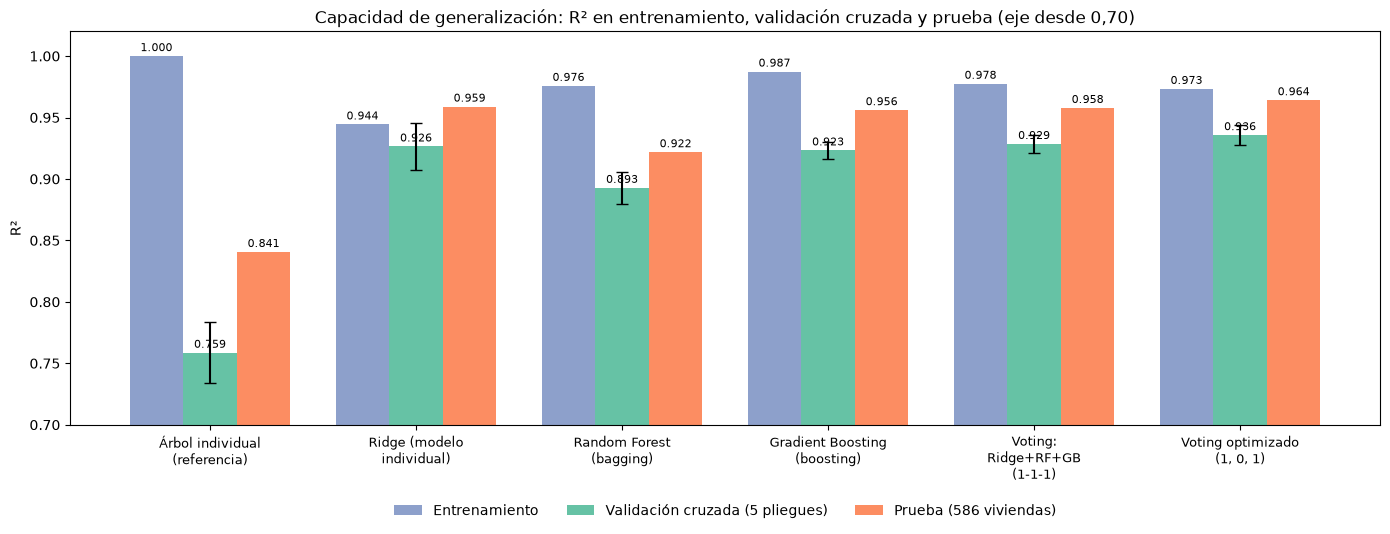

In [15]:
# 4.2 Tabla consolidada de generalización: una sola vista con prueba y validación cruzada
def leer_brecha(b):
    # Criterio orientativo del equipo para leer la brecha de R² (train - evaluación)
    if b < 0:     return "sin sobreajuste"
    if b < 0.02:  return "generaliza muy bien"
    if b < 0.04:  return "sobreajuste leve"
    if b < 0.07:  return "sobreajuste moderado"
    return "sobreajuste alto"

gen = pd.DataFrame({
    "R² train":               tabla_final["R² train"],
    "R² validación cruzada":  resumen_cv["R² validación (media)"],
    "R² test":                tabla_final["R² test"],
    "Brecha train-test":      tabla_final["Brecha R²"],
    "Brecha train-validación (CV)": resumen_cv["Brecha R² media (train - val)"],
    "RMSE validación CV (US$)": resumen_cv["RMSE validación US$ (media)"],
    "RMSE test (US$)":        tabla_final["RMSE test (US$)"],
})
gen["Lectura (brecha en CV)"] = gen["Brecha train-validación (CV)"].map(leer_brecha)
display(gen.round({"R² train": 4, "R² validación cruzada": 4, "R² test": 4, "Brecha train-test": 4,
                   "Brecha train-validación (CV)": 4, "RMSE validación CV (US$)": 0, "RMSE test (US$)": 0}))

# Gráfico: R² en entrenamiento, validación cruzada y prueba
import textwrap
nombres = list(gen.index)
x = np.arange(len(nombres)); w = 0.26
fig, ax = plt.subplots(figsize=(14, 5.5))
b1 = ax.bar(x - w, gen["R² train"], w, label="Entrenamiento", color="#8da0cb")
b2 = ax.bar(x, gen["R² validación cruzada"], w, yerr=resumen_cv["R² validación (desv.)"], capsize=4,
            label="Validación cruzada (5 pliegues)", color="#66c2a5")
b3 = ax.bar(x + w, gen["R² test"], w, label="Prueba (586 viviendas)", color="#fc8d62")
for barras in (b1, b2, b3):
    for b in barras:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.004, f"{b.get_height():.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(["\n".join(textwrap.wrap(n, 18)) for n in nombres], fontsize=9)
ax.set_ylim(0.70, 1.02); ax.set_ylabel("R²")
ax.set_title("Capacidad de generalización: R² en entrenamiento, validación cruzada y prueba (eje desde 0,70)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig("../images/generalizacion_train_cv_test.png", dpi=120)
plt.show()

### Interpretación de la generalización (IE11)

**Qué se midió.** Para cada modelo se comparó el R² en entrenamiento, en validación cruzada de 5 pliegues (solo con el conjunto de entrenamiento) y en el conjunto de prueba. Una brecha pequeña indica que el modelo rinde parecido con datos que no vio; una brecha grande indica que memorizó el entrenamiento.

**Hallazgos**

- **Árbol individual (referencia): no generaliza.** R² de 1,000 en entrenamiento, pero 0,759 en validación cruzada y 0,841 en prueba (brecha en CV de 0,241). Muestra qué ocurre sin ensamble ni regularización.
- **Ridge: la brecha más pequeña.** R² de 0,944 en entrenamiento, 0,927 en validación cruzada y 0,959 en prueba. Su brecha en CV es de 0,018 y en prueba es negativa (−0,015), es decir, no hay sobreajuste. Entre los modelos que cumplen los umbrales es, sin embargo, el de mayor variación entre pliegues (desviación del R² de 0,019 frente a 0,007–0,013 de los demás).
- **Random Forest: el que peor generaliza entre los ensambles.** R² de 0,976 en entrenamiento y 0,893 en validación cruzada (brecha de 0,083, sobreajuste alto según el criterio del equipo) y RMSE de validación de US\$ 25.254.
- **Gradient Boosting: sobreajuste moderado, buen error absoluto.** Brecha de 0,066 en CV y de 0,032 en prueba; R² de validación 0,923 y RMSE de validación US\$ 21.354, algo peor que Ridge (US\$ 20.663).
- **Voting optimizado (1, 0, 1): el menor error con datos no vistos.** R² de validación 0,936 y RMSE de validación de US\$ 19.486 (−5,7% frente a Ridge), con la menor variación entre pliegues (desviación del RMSE de US\$ 722 frente a US\$ 2.004 de Ridge). En prueba: R² de 0,964 y RMSE de US\$ 17.015 (−6,5% frente a Ridge). Su brecha es leve (0,039 en CV y 0,009 en prueba).

**Cómo leer la brecha**

1. En todos los modelos el R² de validación cruzada es menor que el de prueba. Es esperable porque en cada pliegue se entrena con solo el 80% de las filas de entrenamiento (1.873 viviendas), y sugiere que la partición de prueba es algo más favorable que el promedio. Por eso la validación cruzada es la estimación más conservadora del desempeño.
2. Una brecha pequeña no equivale, por sí sola, a mejor modelo: Ridge tiene la menor brecha en parte porque ajusta menos el entrenamiento (su R² de entrenamiento es el más bajo de los modelos finales, 0,944). El criterio completo es **error bajo con datos no vistos y brecha controlada**.

**Conclusión (IE11).** La validación cruzada y el conjunto de prueba coinciden. Los cuatro modelos finales generalizan razonablemente (R² de validación entre 0,89 y 0,94), a diferencia del árbol individual. Ridge es el de menor brecha; el Voting optimizado es el de menor error fuera de muestra y el más consistente entre pliegues.

**Limitaciones.** Los pesos (1, 0, 1) se eligieron con los mismos datos de entrenamiento que luego se usan en la validación cruzada, por lo que el resultado de validación del Voting optimizado está algo favorecido. El conjunto de prueba, usado una sola vez para reportar, confirma el resultado (R² de 0,964). La brecha se interpreta con un criterio orientativo del equipo (menos de 0,02 muy buena; menos de 0,04 leve; menos de 0,07 moderada), no con un umbral estadístico.